# Chapter 1: A classical detector (SIFT + RANSAC)

A copied region has the same texture as its source, so its keypoints have near-identical
descriptors at a consistent offset. This notebook walks one image through the detector,
then shows how the tuning sweep chose its settings.
All logic lives in the `forgery` package; this notebook only calls it and plots.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from forgery.classical import compute_features, draw_masks, group, match, prepare
from forgery.data import build_index, load_image, load_masks
from forgery.metric import score_image
from forgery.split import REPO_ROOT, get_slice

index = build_index()
tune = get_slice("tune", index)
chosen = yaml.safe_load((REPO_ROOT / "configs" / "01_sift.yaml").read_text())["predictor"]["params"]
print("chosen setting:", chosen)

chosen setting: {'max_side': 1024, 'min_distance': 10, 'ransac': True, 'ransac_threshold': 3.0, 'max_groups': 4, 'clahe': True, 'ratio': 0.4, 'min_inliers': 6, 'pad': 10}


## 1. One image, step by step

A forged image from the tuning slice (never validation) that the chosen setting gets right.

In [2]:
def run_steps(image):
    f = compute_features(image, chosen["max_side"], chosen["clahe"])
    pairs = match(f, chosen["ratio"], chosen["min_distance"])
    groups = group(f.points, pairs, chosen["ransac_threshold"], chosen["min_inliers"], chosen["max_groups"])
    masks = draw_masks(f.points, groups, f.scale, f.shape, chosen["pad"])
    return f, pairs, groups, masks


forged = tune[tune.source == "forged"]
for row in forged.itertuples():
    image, gt = load_image(row.image_path), load_masks(row.mask_path)
    f, pairs, groups, masks = run_steps(image)
    if len(gt) == 2 and len(masks) == 2 and score_image(masks, gt) > 0.8:
        break
print(f"case {row.case_id}: {len(f.points)} keypoints, {len(pairs)} matches, {len(groups)} groups, "
      f"score {score_image(masks, gt):.3f}")

case 3073: 10981 keypoints, 76 matches, 2 groups, score 0.902


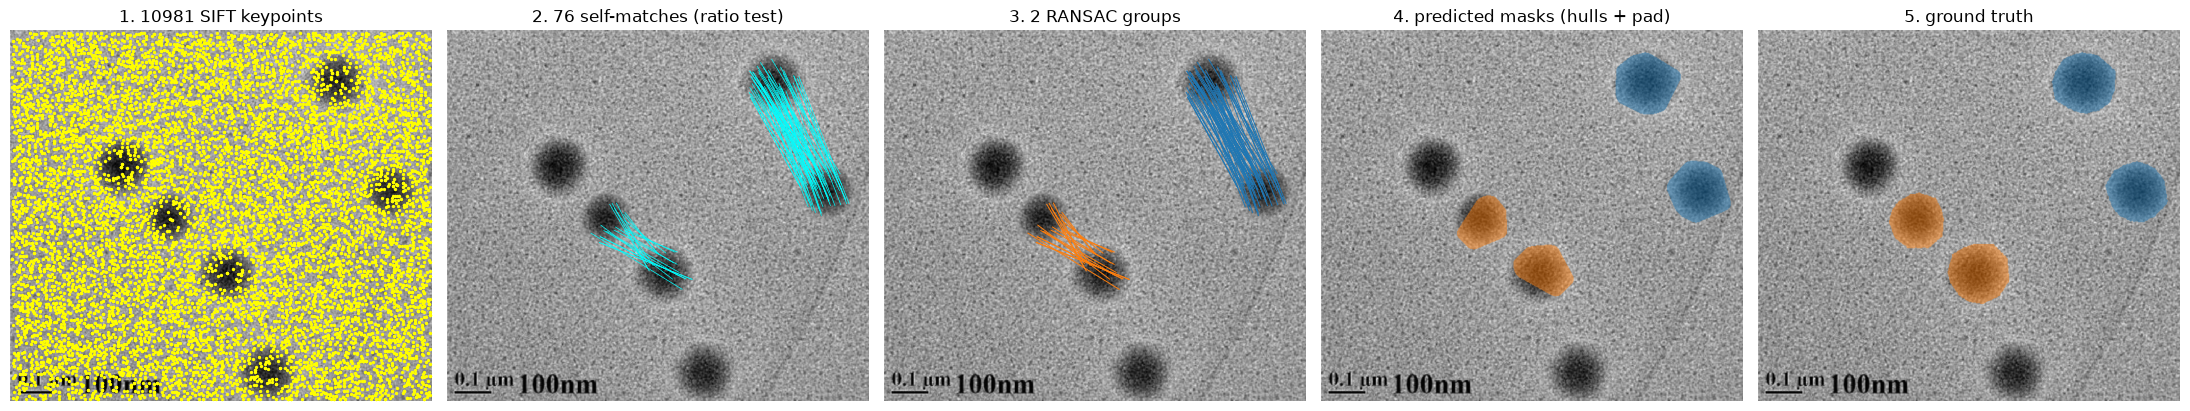

In [3]:
def overlay(image, masks):
    out = image.astype(float) / 255
    colours = plt.cm.tab10.colors
    for k, m in enumerate(masks):
        out[m > 0] = 0.5 * out[m > 0] + 0.5 * np.array(colours[k % 10])
    return out


xy = f.points / f.scale  # back to original-image px
fig, axes = plt.subplots(1, 5, figsize=(22, 5))
axes[0].imshow(image)
axes[0].scatter(xy[:, 0], xy[:, 1], s=2, c="yellow")
axes[0].set_title(f"1. {len(xy)} SIFT keypoints")
axes[1].imshow(image)
for i, j in pairs:
    axes[1].plot(*xy[[i, j]].T, lw=0.5, c="cyan")
axes[1].set_title(f"2. {len(pairs)} self-matches (ratio test)")
axes[2].imshow(image)
for k, g in enumerate(groups):
    for i, j in g:
        axes[2].plot(*xy[[i, j]].T, lw=0.7, c=plt.cm.tab10.colors[k])
axes[2].set_title(f"3. {len(groups)} RANSAC groups")
axes[3].imshow(overlay(image, masks))
axes[3].set_title("4. predicted masks (hulls + pad)")
axes[4].imshow(overlay(image, gt))
axes[4].set_title("5. ground truth")
for ax in axes:
    ax.axis("off")
plt.tight_layout()

Each group's mask is one layer covering both the source and the copy, the same way the
ground truth marks a duplication. Matches that RANSAC can't explain with one movement are
dropped, which is what keeps scattered coincidental matches from becoming false masks.

## 2. Tuning: how the score moves with each knob

All 160 settings were scored on the tuning slice (`experiments/tuning/01_sift.csv`). Each
plot shows, for each value of one knob, the best score over all the other knobs.

160 settings, 1027 images, commit 08aacd3


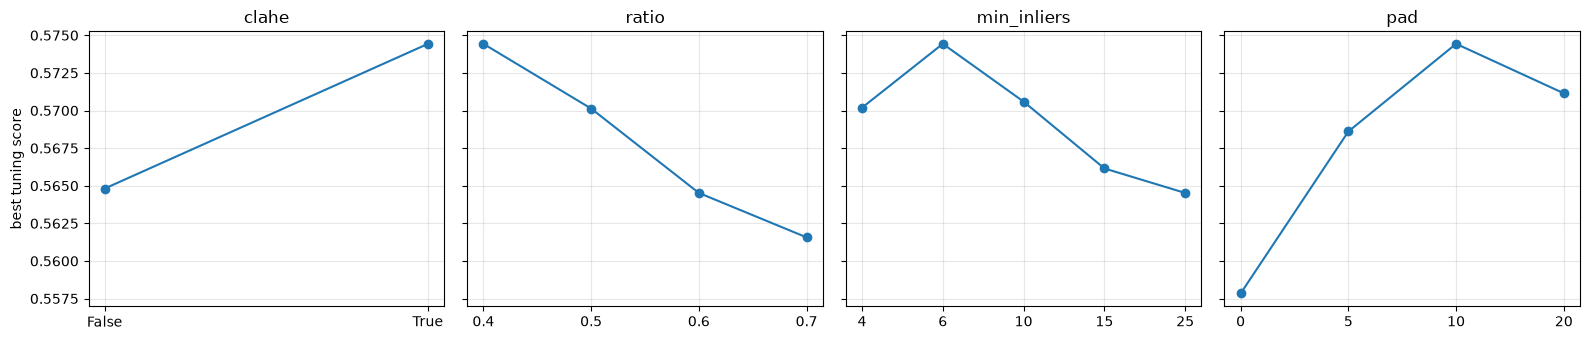

In [4]:
log = pd.read_csv(REPO_ROOT / "experiments" / "tuning" / "01_sift.csv")
print(f"{len(log)} settings, {log.n_images.iloc[0]} images, commit {log.git_commit.iloc[0]}")
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, knob in zip(axes, ["clahe", "ratio", "min_inliers", "pad"]):
    best = log.groupby(knob).score.max()
    ax.plot([str(v) for v in best.index], best.values, marker="o")
    ax.set_title(knob)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("best tuning score")
plt.tight_layout()

In [5]:
columns = ["clahe", "ratio", "min_inliers", "pad", "score", "acc_authentic", "recall_forged", "mean_of1_detected"]
print("Best setting with CLAHE off and on:")
log.loc[log.groupby("clahe").score.idxmax(), columns]

Best setting with CLAHE off and on:


,clahe,ratio,min_inliers,pad,score,acc_authentic,recall_forged,mean_of1_detected
6,False,0.4,6,10,0.564817,0.985294,0.257713,0.782160
86,True,0.4,6,10,0.574433,0.989496,0.277677,0.777405


In [6]:
print("Top 10 settings:")
log.sort_values("score", ascending=False).head(10)[columns]

Top 10 settings:


,clahe,ratio,min_inliers,pad,score,acc_authentic,recall_forged,mean_of1_detected
86,True,0.4,6,10,0.574433,0.989496,0.277677,0.777405
87,True,0.4,6,20,0.571143,0.989496,0.277677,0.755321
90,True,0.4,10,10,0.570589,0.995798,0.237750,0.854926
82,True,0.4,4,10,0.570188,0.974790,0.306715,0.719424
110,True,0.5,10,10,0.570130,0.987395,0.250454,0.837129
106,True,0.5,6,10,0.570001,0.974790,0.295826,0.744733
85,True,0.4,6,5,0.568608,0.989496,0.277677,0.738303
83,True,0.4,4,20,0.567426,0.974790,0.306715,0.702644
109,True,0.5,10,5,0.566937,0.987395,0.250454,0.813364
89,True,0.4,10,5,0.566412,0.995798,0.237750,0.822178


## 3. The three versions on validation

Each version was scored once on validation (`experiments/results.csv`), with the setting
chosen on the tuning slice. The variants remove one piece each and are not re-tuned.

In [7]:
results = pd.read_csv(REPO_ROOT / "experiments" / "results.csv")
summary_cols = ["name", "split", "git_commit", "score", "acc_authentic", "recall_forged", "mean_of1_detected"]
results[results.name.str.startswith(("00_", "01_"))][summary_cols]

,name,split,git_commit,score,acc_authentic,recall_forged,mean_of1_detected
0,00_all_authentic,val,1caa122,0.463415,1.000000,0.000000,NaN
1,00_all_authentic,supplemental,1caa122,0.000000,NaN,0.000000,NaN
2,00_oracle_full_image,val,1caa122,0.503207,1.000000,1.000000,0.074158
3,00_oracle_full_image,supplemental,1caa122,0.130530,NaN,1.000000,0.130530
4,00_oracle_gt,val,1caa122,1.000000,1.000000,1.000000,1.000000
5,00_oracle_gt,supplemental,1caa122,1.000000,NaN,1.000000,1.000000
6,01_sift,val,930b13b,0.570355,1.000000,0.245455,0.811957
7,01_sift,supplemental,930b13b-dirty,0.282588,NaN,0.937500,0.301428
8,01_sift_single_ransac,val,930b13b-dirty,0.559610,1.000000,0.245455,0.730376
9,01_sift_no_ransac,val,930b13b-dirty,0.510532,0.989474,0.278182,0.348338


`acc_authentic` is the share of authentic images left alone, `recall_forged` the share of
forged images flagged at all, and `mean_of1_detected` the mask score on the flagged ones.

Rows marked `930b13b-dirty` ran on the same code as the clean `930b13b` row: the only change
was `results.csv` itself, which the first run had appended to. The dirty check now ignores
the experiment logs.

## 4. Error analysis

The per-image scores of the `01_sift` validation run, joined with facts about each image.
Keypoints and matches are read from the tuning cache (computed by the same code as the run;
`tests/test_tune.py` checks the two agree).

In [8]:
from forgery.cache import get_features

runs = sorted((REPO_ROOT / "experiments" / "runs").glob("*_01_sift"))
val_run = [d for d in runs if yaml.safe_load((d / "config.yaml").read_text())["split"] == "val"][-1]
per_image = pd.read_csv(val_run / "per_image.csv").set_index("sample_id")
print(f"run: {val_run.name}, {len(per_image)} images")

facts = []
for row in index.loc[per_image.index].itertuples():
    f = get_features(row, chosen["max_side"], chosen["clahe"])
    pairs = match(f, chosen["ratio"], chosen["min_distance"])
    found = group(f.points, pairs, chosen["ransac_threshold"], chosen["min_inliers"], chosen["max_groups"])
    gt = load_masks(row.mask_path)
    forged_px = np.any(np.stack(gt), axis=0) if gt else np.zeros((row.height, row.width), bool)
    xy = np.clip(np.round(f.points / f.scale).astype(int), 0, [row.width - 1, row.height - 1])
    gray, _ = prepare(load_image(row.image_path), chosen["max_side"], clahe=False)
    facts.append({
        "sample_id": row.Index,
        "mean_gray": gray.mean(),
        "n_keypoints": len(f.points),
        "kp_in_forged": int(forged_px[xy[:, 1], xy[:, 0]].sum()) if len(xy) else 0,
        "n_matches": len(pairs),
        "n_groups": len(found),
        "forged_area": forged_px.mean(),
    })
val = per_image.join(pd.DataFrame(facts).set_index("sample_id"))
forged_val = val[val.n_gt > 0]
authentic_val = val[val.n_gt == 0]

run: 20261027-124612_01_sift, 1025 images


### Where the misses happen

Each forged image stops at the first step it fails.

In [9]:
stage = np.select(
    [forged_val.n_keypoints < 2, forged_val.n_matches < chosen["min_inliers"], forged_val.n_groups == 0],
    ["no keypoints", f"fewer than {chosen['min_inliers']} matches", "RANSAC found no group"], "detected")
counts = pd.Series(stage).value_counts()
pd.DataFrame({"images": counts, "share": (counts / len(forged_val)).round(3)})

,images,share
fewer than 6 matches,397,0.722
detected,135,0.245
RANSAC found no group,18,0.033


In [10]:
print("Keypoints inside the forged region (median):")
print(forged_val.groupby(forged_val.n_pred > 0).kp_in_forged.median().rename({False: "missed", True: "detected"}))
print("\nMatches per image (median / 90th percentile):")
print(f"  forged:    {forged_val.n_matches.median():.0f} / {forged_val.n_matches.quantile(0.9):.0f}")
print(f"  authentic: {authentic_val.n_matches.median():.0f} / {authentic_val.n_matches.quantile(0.9):.0f}")

Keypoints inside the forged region (median):
n_pred
missed        12.0
detected    1007.0
Name: kp_in_forged, dtype: float64

Matches per image (median / 90th percentile):
  forged:    1 / 283
  authentic: 0 / 2


### Scores by kind of forged image

In [11]:
buckets = {
    "all forged": forged_val.n_gt > 0,
    "dark (mean gray < 40)": forged_val.mean_gray < 40,
    "few keypoints (< 50)": forged_val.n_keypoints < 50,
    "tiny forgery (< 1% of image)": forged_val.forged_area < 0.01,
    "several regions (2+)": forged_val.n_gt >= 2,
}
pd.DataFrame([{"bucket": name, "images": int(m.sum()), "detected": forged_val.n_pred[m].gt(0).mean(),
               "mean score": forged_val.score[m].mean()} for name, m in buckets.items()]).round(3)

,bucket,images,detected,mean score
0,all forged,550,0.245,0.199
1,dark (mean gray < 40),192,0.021,0.009
2,few keypoints (< 50),100,0.000,0.000
3,tiny forgery (< 1% of image),187,0.021,0.015
4,several regions (2+),166,0.217,0.166


In [12]:
by_size = forged_val.groupby(pd.qcut(forged_val.forged_area, 4), observed=True)
pd.DataFrame({"images": by_size.size(), "detected": by_size.n_pred.apply(lambda s: s.gt(0).mean()),
              "mean score": by_size.score.mean()}).rename_axis("forged area (quartiles)").round(3)

,images,detected,mean score
forged area (quartiles),,,
"(2.0000000000000052e-05, 0.00683]",138,0.022,0.015
"(0.00683, 0.0217]",137,0.102,0.059
"(0.0217, 0.0694]",137,0.350,0.277
"(0.0694, 0.423]",138,0.507,0.445


### When it does fire, does it find the right number of regions?

In [13]:
detected = forged_val[forged_val.n_pred > 0]
pd.crosstab(detected.n_pred, detected.n_gt, rownames=["predicted masks"], colnames=["true masks"])

true masks,1,2,3,4
predicted masks,,,,
1,95,8,0,0
2,1,24,1,1
3,2,0,2,0
4,1,0,0,0


### False alarms on authentic images

In [14]:
false_alarms = authentic_val[authentic_val.n_pred > 0]
print(f"{len(false_alarms)} of {len(authentic_val)} authentic images flagged")
print(f"most matches on an authentic image: {authentic_val.n_matches.max()} "
      f"(a group needs {chosen['min_inliers']} RANSAC inliers)")

0 of 475 authentic images flagged
most matches on an authentic image: 8 (a group needs 6 RANSAC inliers)


### Supplemental: the opposite failure

The 48 supplemental images are detected far more often, but score poorly. Predicted vs true
mask counts show why.

In [15]:
sup_run = [d for d in runs if yaml.safe_load((d / "config.yaml").read_text())["split"] == "supplemental"][-1]
sup = pd.read_csv(sup_run / "per_image.csv")
print(f"detected {sup.n_pred.gt(0).mean():.1%}, mean score {sup.score.mean():.3f}")
pd.crosstab(sup.n_pred, sup.n_gt, rownames=["predicted masks"], colnames=["true masks"])

detected 93.8%, mean score 0.283


true masks,1,2,3,4,8,13
predicted masks,,,,,,
0,3,0,0,0,0,0
1,10,0,0,0,0,0
2,1,2,0,0,0,0
3,5,2,1,0,0,0
4,14,5,1,2,1,1


## 5. Gallery

The four best-scoring forged images, then the four largest forgeries it missed entirely
(the most surprising misses). Predicted masks on the left of each pair, truth on the right.

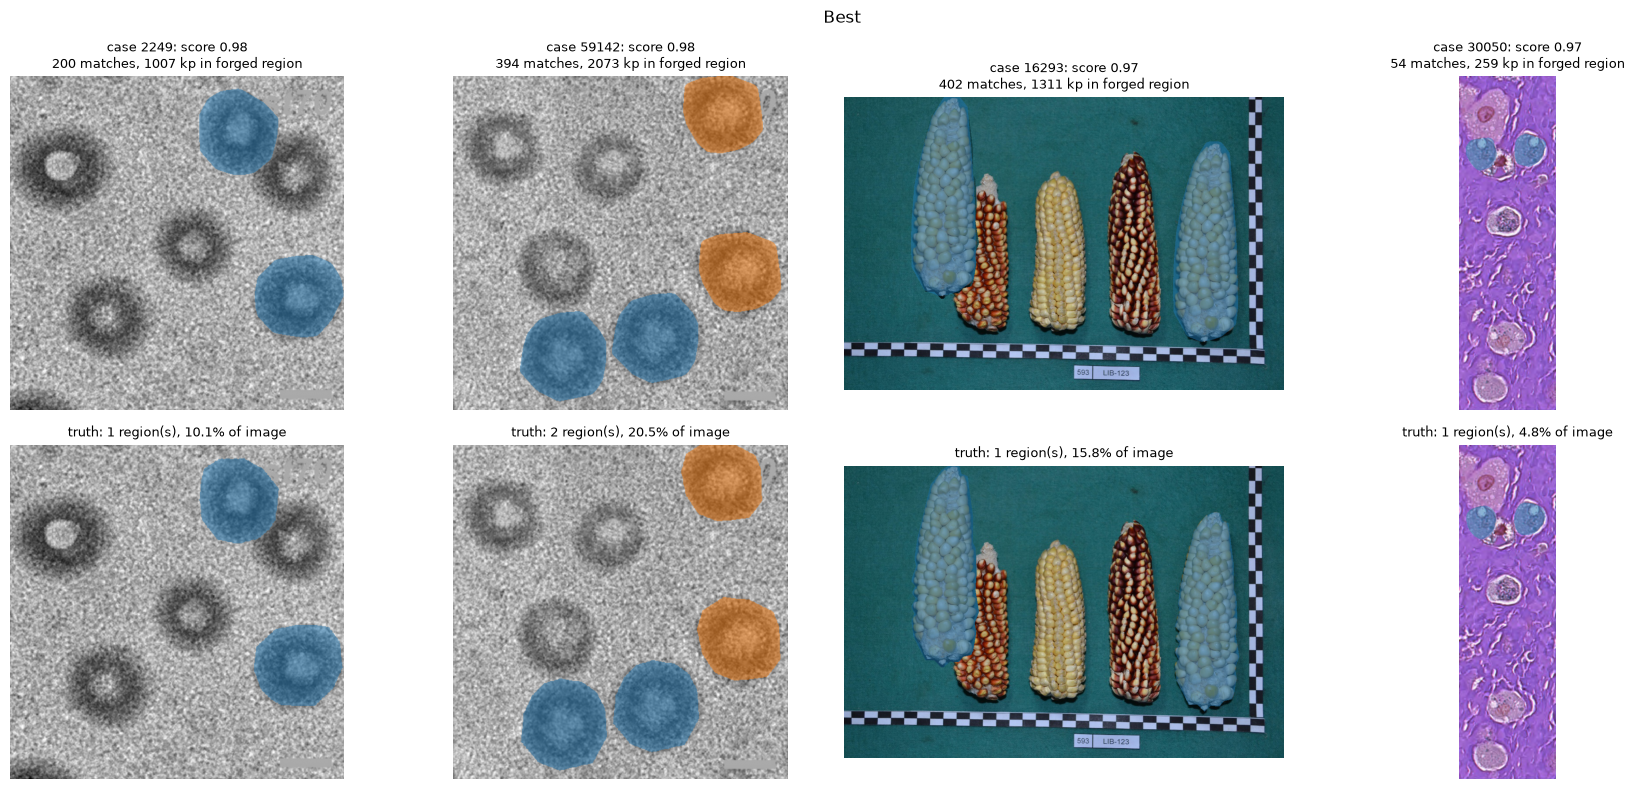

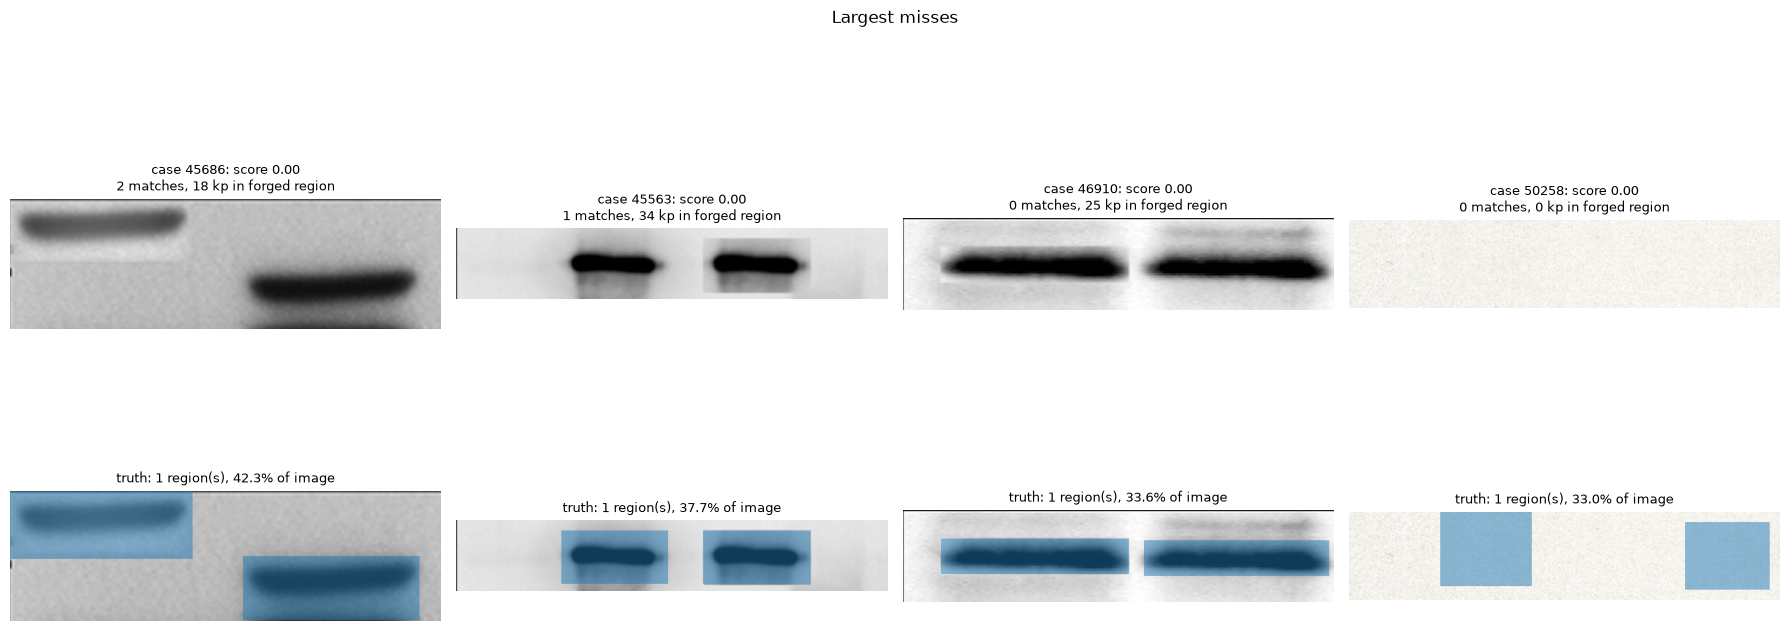

In [16]:
best = forged_val.sort_values("score", ascending=False).head(4)
missed = forged_val[forged_val.n_pred == 0].sort_values("forged_area", ascending=False).head(4)
for title, chosen_rows in (("Best", best), ("Largest misses", missed)):
    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    for col, (sample_id, r) in enumerate(chosen_rows.iterrows()):
        row = index.loc[sample_id]
        image = load_image(row.image_path)
        _, _, _, masks = run_steps(image)
        axes[0, col].imshow(overlay(image, masks))
        axes[0, col].set_title(f"case {row.case_id}: score {r.score:.2f}\n{r.n_matches} matches, "
                               f"{r.kp_in_forged} kp in forged region", fontsize=9)
        axes[1, col].imshow(overlay(image, load_masks(row.mask_path)))
        axes[1, col].set_title(f"truth: {r.n_gt} region(s), {r.forged_area:.1%} of image", fontsize=9)
    for ax in axes.ravel():
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()